# Figure 10 — Global and Cascades comparisons


## 1. Imports and shared 00_Setup

This notebook is standalone, linear, and contains no custom Python functions. It retains the existing populations, filters, missing-data treatment, and panel structure while applying the current 00_Setup: Arial, full axes boxes, 9-point bold uppercase panel labels, 300 dpi PNG export, and editable PDF/SVG text.


In [1]:
from pathlib import Path
import hashlib
import re

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from PIL import Image

SINGLE_COLUMN_WIDTH_IN = 3.55
MAXIMUM_FIGURE_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = SINGLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 7.80
BASE_TEXT_SIZE_PT = 6.0
AXIS_LABEL_SIZE_PT = 7.0
TITLE_SIZE_PT = 7.5
TICK_LABEL_SIZE_PT = 6.0
LEGEND_SIZE_PT = 6.0
PANEL_LABEL_SIZE_PT = 9.0
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required by 00_Setup.')
mpl.rcParams.update({
    'font.family':'sans-serif', 'font.sans-serif':[PUBLICATION_FONT],
    'font.size':BASE_TEXT_SIZE_PT, 'axes.labelsize':AXIS_LABEL_SIZE_PT,
    'axes.titlesize':TITLE_SIZE_PT, 'xtick.labelsize':TICK_LABEL_SIZE_PT,
    'ytick.labelsize':TICK_LABEL_SIZE_PT, 'legend.fontsize':LEGEND_SIZE_PT,
    'legend.title_fontsize':LEGEND_SIZE_PT, 'figure.facecolor':'white',
    'axes.facecolor':'white', 'axes.linewidth':0.5, 'lines.linewidth':0.75,
    'xtick.direction':'in', 'ytick.direction':'in', 'xtick.major.width':0.5,
    'ytick.major.width':0.5, 'pdf.fonttype':42, 'ps.fonttype':42,
    'svg.fonttype':'none', 'savefig.dpi':EXPORT_DPI,
    'savefig.facecolor':'white', 'savefig.transparent':False,
})


## 2. Paths and public S1–S3 workbooks


In [2]:
PROJECT_ROOT_OVERRIDE = None
PROJECT_ROOT = PROJECT_ROOT_OVERRIDE
if PROJECT_ROOT is None:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'SA_MI_Draft_FinalFigures_Work' / 'DataSheets').is_dir():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the project or set PROJECT_ROOT_OVERRIDE.')
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
DATA_DIRECTORY = WORK_ROOT / 'DataSheets' / 'Updated_Oct20'
FIGURE_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_10_Global_Cascades'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_10_Global_Cascades_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
S1_PATH = DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx'
S2_PATH = DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx'
S3_PATH = DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx'
for workbook_path in [S1_PATH,S2_PATH,S3_PATH]:
    if not workbook_path.is_file():
        raise FileNotFoundError(f'Missing supplemental workbook: {workbook_path}')
SOURCE_HASHES_BEFORE = {'S1':hashlib.sha256(S1_PATH.read_bytes()).hexdigest(),'S2':hashlib.sha256(S2_PATH.read_bytes()).hexdigest(),'S3':hashlib.sha256(S3_PATH.read_bytes()).hexdigest()}


## 3. Read the source sheets and set the approved display limits


In [3]:
mi_hosts_plag_pxy = pd.read_excel(S1_PATH, sheet_name='MI_Hosts_Plag_Pxy', header=0)
wieser2023_mi_compilation = pd.read_excel(S3_PATH, sheet_name='Wieser2023_MI_Compilation', header=0)
georoc_global_dacites = pd.read_excel(S3_PATH, sheet_name='GEOROC_GlobalDacites', header=0)

# Check the other public workbook sheets without adding unused data calls.
assert set(['SEM','LA-ICP-MS','SIMS','Whole Rock']).issubset(set(pd.ExcelFile(S2_PATH).sheet_names))
assert set(['Wieser2023_MI_Compilation','GEOROC_GlobalDacites','Kuehn2009','Hoblitt_1987','GVP 2024']).issubset(set(pd.ExcelFile(S3_PATH).sheet_names))

H2O_DISPLAY_MAX = 10.0
CO2_MAX_TRUSTED = 1000.0
SILICA_CUTOFF = 60.0
GLOBAL_MIN_ELIGIBLE_N = 10
HALOGEN_MIN_PAIRED_N = 10
CL_DISPLAY_MAX = 6500.0
F_DISPLAY_MAX = 1500.0
GP_COLOR = '#FF1493'
POINT_SIZE = 12.0
CASCADE_H2O_CO2_METHOD = {'Quinn_2014':'FTIR','Bacon_1992':'FTIR','Mandeville et al. 2010':'FTIR','Wright et al. 2012':'SIMS / FTIR','Blundy et al. 2010 EPSL':'SIMS','Koleszar_2012':'SIMS / FTIR'}
MISSING_TOKENS = {'':'nan',' ':'nan','nd':'nan','ND':'nan','n.d.':'nan','N.D.':'nan','nan':'nan','NaN':'nan'}


## 4. Harmonize the three plotted populations


In [4]:
georoc_global_dacites = georoc_global_dacites.astype(str).fillna('')


In [5]:
wieser2023_mi_compilation['f_raw_ppm'] = np.nan


/var/folders/5k/6pnfdpxn5419w3kg2f6c8pwc0000gn/T/ipykernel_10198/2883236326.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  wieser2023_mi_compilation['f_raw_ppm'] = np.nan


In [6]:
mi_hosts_plag_pxy['base_name'] = mi_hosts_plag_pxy['base_name'].astype(str).str.replace('_MTX',' MTX',regex=False)


In [7]:
global_raw = georoc_global_dacites.copy()
cascade_raw = wieser2023_mi_compilation.copy()
gp_raw = mi_hosts_plag_pxy.copy()

glob_all = pd.DataFrame(index=global_raw.index)
glob_all['dataset'] = 'Global dacites'
glob_all['source'] = global_raw['CITATION'].fillna('Source not reported').astype(str)
glob_all['volcano'] = global_raw['LOCATION'].astype('string').fillna('Location not reported').str.split('/').str[-1].str.strip().str.title().replace({'Mount Mazama':'Mazama','Mt. Mazama':'Mazama','Heisei Lavas':'Unzen'})
global_host = global_raw['HOSTMINERAL (INCLUSION)'].astype('string')
global_host_text = global_host.fillna('').str.strip().str.lower()
glob_all['host'] = np.select([global_host_text.eq('') | global_host_text.isin(['nan','nd','none']),global_host_text.str.contains('plag|feldspar',regex=True,na=False),global_host_text.str.contains('pyrox|^px$|^pxy$|^opx$|^cpx$',regex=True,na=False),global_host_text.str.contains('amph|hornblende',regex=True,na=False),global_host_text.str.contains('oliv',regex=True,na=False),global_host_text.str.contains('quartz',regex=True,na=False),global_host_text.str.contains('biot',regex=True,na=False),global_host_text.str.contains('apat',regex=True,na=False)],['Host not reported','Plagioclase','Pyroxene','Amphibole','Olivine','Quartz','Biotite','Apatite'],default=global_host.fillna('').astype(str).str.strip().str.title())
glob_all['h2o_wt'] = pd.to_numeric(global_raw['H2O(WT%): altern. values or methods'].replace(MISSING_TOKENS),errors='coerce')
glob_all['co2_ppm'] = pd.to_numeric(global_raw['CO2(PPM)'].replace(MISSING_TOKENS),errors='coerce')
global_cl_ppm = pd.to_numeric(global_raw['CL(PPM): altern. values or methods'].replace(MISSING_TOKENS),errors='coerce')
global_cl_wt = pd.to_numeric(global_raw['CL(WT%): altern. values or methods'].replace(MISSING_TOKENS),errors='coerce') * 10000.0
glob_all['cl_ppm_raw'] = global_cl_ppm.where(global_cl_ppm.notna(),global_cl_wt)
global_f_ppm = pd.to_numeric(global_raw['F(PPM): altern. values or methods'].replace(MISSING_TOKENS),errors='coerce')
global_f_wt = pd.to_numeric(global_raw['F(WT%): altern. values or methods'].replace(MISSING_TOKENS),errors='coerce') * 10000.0
glob_all['f_ppm_raw'] = global_f_ppm.where(global_f_ppm.notna(),global_f_wt)
global_method_text = global_raw.astype(str).agg(' | '.join,axis=1).str.upper()
glob_all['method'] = np.select([global_method_text.str.contains(r'EPMA|\bEMP\b|ELECTRON[ -]?MICROPROBE',regex=True,na=False),global_method_text.str.contains(r'FTIR|FOURIER',regex=True,na=False),global_method_text.str.contains(r'\bSIMS\b|ION MICROPROBE',regex=True,na=False),global_method_text.str.contains(r'ICP[ -]?MS',regex=True,na=False)],['EMP/EPMA','FTIR','SIMS','ICP-MS'],default='Other / unreported')

cas_all = pd.DataFrame(index=cascade_raw.index)
cas_all['dataset'] = 'Cascades >60 wt% SiO2'
cas_all['source'] = cascade_raw['reference'].fillna('Source not reported').astype(str)
cas_all['volcano'] = cascade_raw['volcano'].astype('string').fillna('Location not reported').str.split('/').str[-1].str.strip().str.title().replace({'Mount Mazama':'Mazama','Mt. Mazama':'Mazama','Heisei Lavas':'Unzen'})
cascade_host = cascade_raw['host_mineral'].astype('string')
cascade_host_text = cascade_host.fillna('').str.strip().str.lower()
cas_all['host'] = np.select([cascade_host_text.eq('') | cascade_host_text.isin(['nan','nd','none']),cascade_host_text.str.contains('plag|feldspar',regex=True,na=False),cascade_host_text.str.contains('pyrox|^px$|^pxy$|^opx$|^cpx$',regex=True,na=False),cascade_host_text.str.contains('amph|hornblende',regex=True,na=False),cascade_host_text.str.contains('oliv',regex=True,na=False),cascade_host_text.str.contains('quartz',regex=True,na=False),cascade_host_text.str.contains('biot',regex=True,na=False),cascade_host_text.str.contains('apat',regex=True,na=False)],['Host not reported','Plagioclase','Pyroxene','Amphibole','Olivine','Quartz','Biotite','Apatite'],default=cascade_host.fillna('').astype(str).str.strip().str.title())
cas_all['sio2_wt'] = pd.to_numeric(cascade_raw['sio2_raw_wt'].replace(MISSING_TOKENS),errors='coerce')
cas_h2o_pec = pd.to_numeric(cascade_raw['h2o_pec_wt'].replace(MISSING_TOKENS),errors='coerce')
cas_h2o_raw = pd.to_numeric(cascade_raw['h2o_raw_wt'].replace(MISSING_TOKENS),errors='coerce')
cas_all['h2o_wt'] = cas_h2o_pec.fillna(cas_h2o_raw)
cas_co2_pec = pd.to_numeric(cascade_raw['co2_glass_pec_ppm'].replace(MISSING_TOKENS),errors='coerce')
cas_co2_raw = pd.to_numeric(cascade_raw['co2_glass_raw_ppm'].replace(MISSING_TOKENS),errors='coerce')
cas_all['co2_ppm'] = cas_co2_pec.fillna(cas_co2_raw)
cas_cl_pec = pd.to_numeric(cascade_raw['cl_pec_ppm'].replace(MISSING_TOKENS),errors='coerce')
cas_cl_raw = pd.to_numeric(cascade_raw['cl_raw_ppm'].replace(MISSING_TOKENS),errors='coerce')
cas_cl_wt = pd.to_numeric(cascade_raw['cl_pec_wt'].replace(MISSING_TOKENS),errors='coerce').fillna(pd.to_numeric(cascade_raw['cl_raw_wt'].replace(MISSING_TOKENS),errors='coerce')) * 10000.0
cas_all['cl_ppm_raw'] = cas_cl_pec.fillna(cas_cl_raw).fillna(cas_cl_wt)
cas_f_pec = pd.to_numeric(cascade_raw['f_pec_ppm'].replace(MISSING_TOKENS),errors='coerce')
cas_f_pec1 = pd.to_numeric(cascade_raw['f_pec_ppm1'].replace(MISSING_TOKENS),errors='coerce')
cas_f_raw = pd.to_numeric(cascade_raw['f_raw_ppm'].replace(MISSING_TOKENS),errors='coerce')
cas_f_wt = pd.to_numeric(cascade_raw['f_pec_wt'].replace(MISSING_TOKENS),errors='coerce').fillna(pd.to_numeric(cascade_raw['f_raw_wt'].replace(MISSING_TOKENS),errors='coerce')) * 10000.0
cas_all['f_ppm_raw'] = cas_f_pec.fillna(cas_f_pec1).fillna(cas_f_raw).fillna(cas_f_wt)
cas_all['method'] = cascade_raw['reference'].map(CASCADE_H2O_CO2_METHOD).fillna('Other / unreported')
cas_all_full = cas_all.copy()

gp_discard_mask = gp_raw['Discard_SIMS'].astype('string').str.strip().str.casefold().eq('yes').fillna(False)
gp_matrix_text = (gp_raw['mineral_phase'].astype('string').fillna('') + ' ' + gp_raw['base_name'].astype('string').fillna('')).str.strip().str.casefold()
gp_matrix_mask = gp_matrix_text.str.contains(r'(^|\s)mtx($|\s)|matrix glass|groundmass glass|interstitial glass',regex=True,na=False)
gp_work = gp_raw.loc[~gp_discard_mask & ~gp_matrix_mask].copy()
gp_all = pd.DataFrame(index=gp_work.index)
gp_all['dataset'] = 'Glacier Peak (this study)'
gp_all['source'] = 'This study'
gp_all['volcano'] = 'Glacier Peak'
gp_host = gp_work['mineral_phase'].astype('string')
gp_host_text = gp_host.fillna('').str.strip().str.lower()
gp_all['host'] = np.select([gp_host_text.str.contains('plag|feldspar',regex=True,na=False),gp_host_text.str.contains('pyrox|^px$|^pxy$|^opx$|^cpx$',regex=True,na=False),gp_host_text.str.contains('amph|hornblende',regex=True,na=False),gp_host_text.str.contains('oliv',regex=True,na=False),gp_host_text.str.contains('quartz',regex=True,na=False),gp_host_text.str.contains('biot',regex=True,na=False),gp_host_text.str.contains('apat',regex=True,na=False)],['Plagioclase','Pyroxene','Amphibole','Olivine','Quartz','Biotite','Apatite'],default=gp_host.fillna('').astype(str).str.strip().str.title())
gp_all['h2o_wt'] = pd.to_numeric(gp_work['H2O matrix wt% USE_SIMS'].replace(MISSING_TOKENS),errors='coerce')
gp_all['co2_ppm'] = pd.to_numeric(gp_work['Total_CO2_ppm_final'].replace(MISSING_TOKENS),errors='coerce')
gp_all['cl_ppm_raw'] = pd.to_numeric(gp_work['Cl_mtx ppm_SIMS'].replace(MISSING_TOKENS),errors='coerce')
gp_all['f_ppm_raw'] = pd.to_numeric(gp_work['F_mtx ppm_SIMS'].replace(MISSING_TOKENS),errors='coerce')
gp_all['method'] = 'SIMS'

for frame in [glob_all,cas_all_full,gp_all]:
    frame['co2_reported'] = frame['co2_ppm'].notna()
    frame['co2_over_limit'] = frame['co2_ppm'] > CO2_MAX_TRUSTED
    frame['h2o_overflow'] = frame['h2o_wt'] > H2O_DISPLAY_MAX
    frame['h2o_plot_wt'] = frame['h2o_wt'].clip(upper=H2O_DISPLAY_MAX)
    frame['cl_ppm'] = frame['cl_ppm_raw']
    frame['f_ppm'] = frame['f_ppm_raw']
for frame in [glob_all,cas_all_full]:
    frame['cl_nonpositive_excluded'] = frame['cl_ppm_raw'].notna() & frame['cl_ppm_raw'].le(0)
    frame['f_nonpositive_excluded'] = frame['f_ppm_raw'].notna() & frame['f_ppm_raw'].le(0)
    frame.loc[frame['cl_nonpositive_excluded'],'cl_ppm'] = np.nan
    frame.loc[frame['f_nonpositive_excluded'],'f_ppm'] = np.nan
gp_all['cl_nonpositive_excluded'] = False
gp_all['f_nonpositive_excluded'] = False
cas_all = cas_all_full.loc[cas_all_full['sio2_wt'] > SILICA_CUTOFF].copy()
blatter_reference_mask = cas_all_full['source'].astype('string').str.contains('Blatter',case=False,na=False)
blatter_h2o_only_mask = blatter_reference_mask & cas_all_full['volcano'].eq('Mount St. Helens') & cas_all_full['h2o_wt'].notna() & cas_all_full['h2o_wt'].ge(0) & cas_all_full['co2_ppm'].isna()
cas_blatter_h2o_only = cas_all_full.loc[blatter_h2o_only_mask].copy()

global_top_eligible = glob_all['h2o_wt'].notna() & glob_all['h2o_wt'].ge(0) & ~glob_all['co2_over_limit']
global_top_counts = glob_all.loc[global_top_eligible].groupby('volcano').size()
global_top_systems = global_top_counts.loc[global_top_counts >= GLOBAL_MIN_ELIGIBLE_N].index
glob_top = glob_all.loc[glob_all['volcano'].isin(global_top_systems)].copy()
global_pair_eligible = glob_all['cl_ppm'].notna() & glob_all['f_ppm'].notna()
global_pair_counts = glob_all.loc[global_pair_eligible].groupby('volcano').size()
global_bottom_systems = global_pair_counts.loc[global_pair_counts >= HALOGEN_MIN_PAIRED_N].index
glob_bottom = glob_all.loc[glob_all['volcano'].isin(global_bottom_systems)].copy()
cas_top = cas_all.copy()
cas_jitter_pool = pd.concat([cas_top,cas_blatter_h2o_only],axis=0).sort_index()
gp_top = gp_all.copy()
gp_bottom = gp_all.copy()
represented_literature_volcanoes = sorted(set(glob_top['volcano']) | set(cas_top['volcano']) | set(glob_bottom['volcano']),key=str.casefold)
JEWEL_TONE_PALETTE = ['#D4A017','#8C4B2D','#1F4E9E','#7B2CBF','#00796B','#E85D04','#5145CD','#168AAD','#C1121F','#00A896','#7F1D1D','#6A0572','#2E7D32','#708238']
if len(represented_literature_volcanoes) != len(JEWEL_TONE_PALETTE):
    raise ValueError(f'Expected {len(JEWEL_TONE_PALETTE)} represented literature volcanoes; found {len(represented_literature_volcanoes)}')
VOLCANO_COLORS = dict(zip(represented_literature_volcanoes,JEWEL_TONE_PALETTE))
VOLCANO_COLORS['Glacier Peak'] = GP_COLOR
VOLCANO_MARKER_SEQUENCE = ['s','^','D','v','P','X','*','<','>','p','h','H','8','d']
other_volcanoes = sorted([name for name in VOLCANO_COLORS if name != 'Glacier Peak'],key=str.casefold)
if len(other_volcanoes) != len(VOLCANO_MARKER_SEQUENCE):
    raise ValueError(f'Expected {len(VOLCANO_MARKER_SEQUENCE)} non-GP volcanoes; found {len(other_volcanoes)}')
VOLCANO_MARKERS = {'Glacier Peak':'o'}
VOLCANO_MARKERS.update(dict(zip(other_volcanoes,VOLCANO_MARKER_SEQUENCE)))
HOST_MARKERS = {'Plagioclase':'o','Pyroxene':'s','Amphibole':'^','Olivine':'D','Quartz':'P','Biotite':'v','Apatite':'*','Host not reported':'h'}
retained_frames = [glob_top,cas_top,glob_bottom,gp_all]
hosts_present = sorted(set().union(*(set(frame['host'].dropna()) for frame in retained_frames)),key=str.casefold)
extra_hosts = [host for host in hosts_present if host not in HOST_MARKERS]
EXTRA_MARKER_SEQUENCE = ['<','>','H','8','p','d','X']
if len(extra_hosts) > len(EXTRA_MARKER_SEQUENCE):
    raise ValueError(f'More extra host labels than deterministic markers: {extra_hosts}')
for host,marker in zip(extra_hosts,EXTRA_MARKER_SEQUENCE):
    HOST_MARKERS[host] = marker

# Apply the same method classes used in the original audit, without a helper function.
method_audit_rows = []
for panel,source_class,frame in [('A','Literature',glob_top),('A','Glacier Peak',gp_top),('B','Literature',cas_top),('B','Glacier Peak',gp_top),('C','Literature',glob_bottom),('C','Glacier Peak',gp_bottom)]:
    method_text = frame['method'].astype('string').str.upper()
    method_class = np.select([method_text.str.contains('SIMS',na=False),method_text.str.contains('FTIR',na=False),method_text.str.contains('ICP',na=False) & method_text.str.contains('MS',na=False),method_text.str.contains('EMP|EPMA',regex=True,na=False)],['SIMS','FTIR','ICP-MS','EMP/EPMA'],default='Other / unreported')
    method_audit_rows.append(pd.DataFrame({'panel':panel,'source_class':source_class,'method_class':method_class}))
method_audit = pd.concat(method_audit_rows,ignore_index=True).groupby(['panel','source_class','method_class']).size().reset_index(name='retained_rows')
represented_method_classes = set(method_audit['method_class'])

assert 'Other / unreported' not in represented_method_classes
assert len(cas_blatter_h2o_only) == 24
assert cas_blatter_h2o_only['co2_ppm'].isna().all()
assert cas_blatter_h2o_only['h2o_wt'].between(2.84,6.52).all()
assert represented_method_classes.issubset({'SIMS','FTIR','ICP-MS','EMP/EPMA'})
assert len(gp_all) == 186
assert int(gp_discard_mask.sum()) == 13
assert int(gp_matrix_mask.sum()) == 13
assert VOLCANO_COLORS['Glacier Peak'].lower() == '#ff1493'
assert len({HOST_MARKERS[host] for host in hosts_present}) == len(hosts_present)
assert len(set(VOLCANO_MARKERS.values())) == len(VOLCANO_MARKERS)
assert all(global_pair_counts.loc[global_bottom_systems] >= HALOGEN_MIN_PAIRED_N)
print(f'Glacier Peak filter: {len(gp_raw)} source - {int(gp_discard_mask.sum())} discard - {int(gp_matrix_mask.sum())} matrix = {len(gp_all)} retained')
print('Global H2O-CO2 systems:',list(global_top_systems))
print('Global Cl-F systems:',list(global_bottom_systems))


Glacier Peak filter: 212 source - 13 discard - 13 matrix = 186 retained
Global H2O-CO2 systems: ['Altiplano-Puna Volcanic Complex', 'Dzarta-Kuduk Paleovolcano', 'Ichinsky(Ichinskii)', 'Iturup (Itirup)', 'Mazama', 'Pinatubo', 'Plat Pays', 'Popocatepetl', 'Santorini', 'Suphan Dag', 'Unzen']
Global Cl-F systems: ['Altiplano-Puna Volcanic Complex', 'Dzarta-Kuduk Paleovolcano', 'Mazama', 'Santorini']


/var/folders/5k/6pnfdpxn5419w3kg2f6c8pwc0000gn/T/ipykernel_10198/4176637312.py:51: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  gp_matrix_mask = gp_matrix_text.str.contains(r'(^|\s)mtx($|\s)|matrix glass|groundmass glass|interstitial glass',regex=True,na=False)


## 5. Audit the retained populations


In [8]:
panel_audit_rows = []
for panel,dataset,data,source_rows in [('A','Global dacites',glob_top,len(global_raw)),('A','Glacier Peak',gp_top,len(gp_raw)),('B','Cascades',cas_jitter_pool,len(cascade_raw)),('B','Glacier Peak',gp_top,len(gp_raw)),('C','Global dacites',glob_bottom,len(global_raw)),('C','Glacier Peak',gp_bottom,len(gp_raw))]:
    x_h2o = data['h2o_wt'].notna() & data['h2o_wt'].ge(0)
    positive_co2 = data['co2_ppm'].notna() & data['co2_ppm'].gt(0) & ~data['co2_over_limit']
    cl_ok = data['cl_ppm'].notna() & data['cl_ppm'].ge(0) & data['cl_ppm'].le(CL_DISPLAY_MAX)
    f_ok = data['f_ppm'].notna() & data['f_ppm'].ge(0) & data['f_ppm'].le(F_DISPLAY_MAX)
    panel_audit_rows.append({'panel':panel,'dataset':dataset,'source_rows':int(source_rows),'panel_frame_rows':len(data),'valid_H2O':int(x_h2o.sum()),'valid_CO2':int(data['co2_ppm'].notna().sum()),'central_scatter':int((positive_co2 if panel in ['A','B'] else (cl_ok & f_ok)).sum()),'CO2_missing_or_zero_jitter_strip':int((x_h2o & (data['co2_ppm'].isna() | data['co2_ppm'].eq(0))).sum()),'missing_Cl':int(data['cl_ppm_raw'].isna().sum()),'missing_F':int(data['f_ppm_raw'].isna().sum())})
panel_audit = pd.DataFrame(panel_audit_rows)
volcano_encoding_audit = pd.DataFrame({'volcanic_system':sorted(set(glob_top['volcano']) | set(cas_top['volcano']) | set(glob_bottom['volcano']) | {'Glacier Peak'},key=str.casefold)})
volcano_encoding_audit['color'] = volcano_encoding_audit['volcanic_system'].map(VOLCANO_COLORS)
volcano_encoding_audit['marker'] = volcano_encoding_audit['volcanic_system'].map(VOLCANO_MARKERS)
print(panel_audit.to_string(index=False))


panel        dataset  source_rows  panel_frame_rows  valid_H2O  valid_CO2  central_scatter  CO2_missing_or_zero_jitter_strip  missing_Cl  missing_F
    A Global dacites          450               414        412         77               77                               335          64        208
    A   Glacier Peak          212               186        116        116              116                                 0          70         70
    B       Cascades          756               346        346        322              213                               121          24        346
    B   Glacier Peak          212               186        116        116              116                                 0          70         70
    C Global dacites          450               207        207         68              167                               139           9         24
    C   Glacier Peak          212               186        116        116              116                      

## 6. Build the three panels and export


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_10_Global_Cascades/Figure_10_Global_Cascades_Final/Figure_10_H2O_CO2_and_Cl_F_Comparison


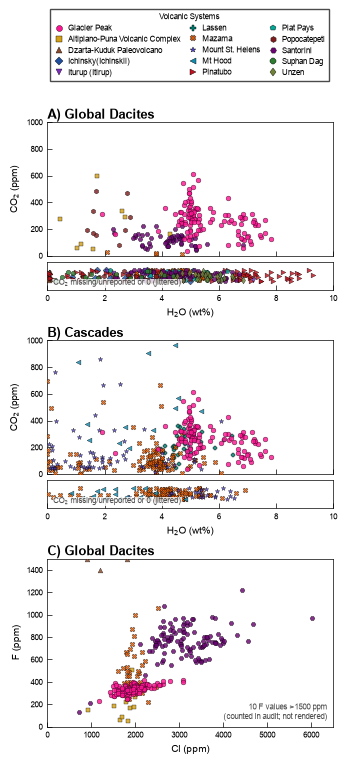

In [9]:
JITTER_SEED = 20260916
CO2_STRIP_LABEL = 'CO$_2$ missing/unreported or 0 (jittered)'
fig = plt.figure(figsize=(FIGURE_WIDTH_IN,FIGURE_HEIGHT_IN))
outer = fig.add_gridspec(3,1,left=0.17,right=0.975,top=0.84,bottom=0.065,hspace=0.30)
panel_axes = {}
plotted_frames = {}

# Panel A: global dacites.
inner_a = outer[0,0].subgridspec(2,1,height_ratios=[3.30,0.70],hspace=0.075)
ax_a = fig.add_subplot(inner_a[0,0])
strip_a = fig.add_subplot(inner_a[1,0],sharex=ax_a)
for data,zorder in [(glob_top,3),(gp_top,5)]:
    x_ok = data['h2o_wt'].notna() & data['h2o_wt'].ge(0)
    y_ok = data['co2_ppm'].notna() & data['co2_ppm'].gt(0) & ~data['co2_over_limit']
    plotted = data.loc[x_ok & y_ok].copy()
    for volcano,group in plotted.groupby('volcano',dropna=False):
        ax_a.scatter(group['h2o_wt'],group['co2_ppm'],s=POINT_SIZE,marker=VOLCANO_MARKERS[volcano],facecolors=VOLCANO_COLORS[volcano],edgecolors='black',linewidths=0.28,alpha=0.82,zorder=zorder)
    if data is glob_top:
        plotted_frames['a_literature'] = plotted
    else:
        plotted_frames['a_gp'] = plotted
for data,seed,zorder,key in [(glob_top,JITTER_SEED,3,'a_strip_literature'),(gp_top,JITTER_SEED+1,5,'a_strip_gp')]:
    x_ok = data['h2o_wt'].notna() & data['h2o_wt'].ge(0)
    mask = x_ok & (data['co2_ppm'].isna() | data['co2_ppm'].eq(0))
    plotted = data.loc[mask].copy()
    rng = np.random.default_rng(seed)
    plotted['jitter_y'] = rng.uniform(0.3,0.72,size=len(plotted))
    for volcano,group in plotted.groupby('volcano',dropna=False):
        strip_a.scatter(group['h2o_wt'],group['jitter_y'],s=POINT_SIZE,marker=VOLCANO_MARKERS[volcano],facecolors=VOLCANO_COLORS[volcano],edgecolors='black',linewidths=0.28,alpha=0.82,zorder=zorder)
    plotted_frames[key] = plotted
ax_a.set_xlim(0,H2O_DISPLAY_MAX); ax_a.set_ylim(0,CO2_MAX_TRUSTED); ax_a.set_ylabel('CO$_2$ (ppm)'); ax_a.tick_params(direction='in',top=False,right=False,labelbottom=False); ax_a.grid(False); ax_a.set_title('A) Global Dacites',loc='left',pad=2.5,fontweight='bold',fontsize=PANEL_LABEL_SIZE_PT)
strip_a.set_xlim(0,H2O_DISPLAY_MAX); strip_a.set_ylim(0,1); strip_a.set_yticks([]); strip_a.set_xlabel('H$_2$O (wt%)'); strip_a.tick_params(direction='in',top=False,right=False); strip_a.grid(False); strip_a.text(0.02,0.1,CO2_STRIP_LABEL,transform=strip_a.transAxes,ha='left',va='bottom',fontsize=5.5,color='0.30',bbox={'facecolor':'white','edgecolor':'none','alpha':0.82,'pad':0.45})
volcano_names = set(glob_top['volcano']) | set(cas_top['volcano']) | set(glob_bottom['volcano']) | {'Glacier Peak'}
ordered_volcanoes = (['Glacier Peak'] if 'Glacier Peak' in volcano_names else []) + sorted([name for name in volcano_names if name != 'Glacier Peak'],key=str.casefold)
volcano_handles = [Line2D([0],[0],linestyle='none',marker=VOLCANO_MARKERS[name],markersize=4.3,markerfacecolor=VOLCANO_COLORS[name],markeredgecolor='black',markeredgewidth=0.28,label=name) for name in ordered_volcanoes]
volcano_legend = fig.legend(handles=volcano_handles,title='Volcanic Systems',loc='upper center',bbox_to_anchor=(0.57,0.985),ncol=3,fontsize=LEGEND_SIZE_PT,title_fontsize=LEGEND_SIZE_PT,frameon=True,fancybox=False,framealpha=0.94,facecolor='white',edgecolor='0.25',borderaxespad=0.0,borderpad=0.45,handlelength=1.2,handletextpad=0.5,labelspacing=0.35,columnspacing=0.9)
panel_axes['a']={'scatter':ax_a,'strip':strip_a,'legend':volcano_legend}

# Panel B: Cascades with the matching missing-or-zero CO2 strip.
inner_b = outer[1,0].subgridspec(2,1,height_ratios=[3.30,0.70],hspace=0.075)
ax_b = fig.add_subplot(inner_b[0,0])
strip_b = fig.add_subplot(inner_b[1,0],sharex=ax_b)
for data,zorder,key in [(cas_top,3,'b_literature'),(gp_top,5,'b_gp')]:
    x_ok = data['h2o_wt'].notna() & data['h2o_wt'].ge(0)
    y_ok = data['co2_ppm'].notna() & data['co2_ppm'].gt(0) & ~data['co2_over_limit']
    plotted = data.loc[x_ok & y_ok].copy()
    for volcano,group in plotted.groupby('volcano',dropna=False):
        ax_b.scatter(group['h2o_wt'],group['co2_ppm'],s=POINT_SIZE,marker=VOLCANO_MARKERS[volcano],facecolors=VOLCANO_COLORS[volcano],edgecolors='black',linewidths=0.28,alpha=0.82,zorder=zorder)
    plotted_frames[key] = plotted
for data,seed,zorder,key in [(cas_jitter_pool,JITTER_SEED+2,3,'b_strip_literature'),(gp_top,JITTER_SEED+3,5,'b_strip_gp')]:
    x_ok = data['h2o_wt'].notna() & data['h2o_wt'].ge(0)
    mask = x_ok & (data['co2_ppm'].isna() | data['co2_ppm'].eq(0))
    plotted = data.loc[mask].copy()
    rng = np.random.default_rng(seed)
    plotted['jitter_y'] = rng.uniform(0.3,0.72,size=len(plotted))
    for volcano,group in plotted.groupby('volcano',dropna=False):
        strip_b.scatter(group['h2o_wt'],group['jitter_y'],s=POINT_SIZE,marker=VOLCANO_MARKERS[volcano],facecolors=VOLCANO_COLORS[volcano],edgecolors='black',linewidths=0.28,alpha=0.82,zorder=zorder)
    plotted_frames[key] = plotted
ax_b.set_xlim(0,H2O_DISPLAY_MAX); ax_b.set_ylim(0,CO2_MAX_TRUSTED); ax_b.set_ylabel('CO$_2$ (ppm)'); ax_b.tick_params(direction='in',top=False,right=False,labelbottom=False); ax_b.grid(False); ax_b.set_title('B) Cascades',loc='left',pad=2.5,fontweight='bold',fontsize=PANEL_LABEL_SIZE_PT)
strip_b.set_xlim(0,H2O_DISPLAY_MAX); strip_b.set_ylim(0,1); strip_b.set_yticks([]); strip_b.set_xlabel('H$_2$O (wt%)'); strip_b.tick_params(direction='in',top=False,right=False); strip_b.grid(False); strip_b.text(0.02,0.1,CO2_STRIP_LABEL,transform=strip_b.transAxes,ha='left',va='bottom',fontsize=5.5,color='0.30',bbox={'facecolor':'white','edgecolor':'none','alpha':0.82,'pad':0.45})
panel_axes['b']={'scatter':ax_b,'strip':strip_b}

# Panel C: paired global Cl-F comparison.
ax_c = fig.add_subplot(outer[2,0])
for data,zorder,key in [(glob_bottom,3,'c_literature'),(gp_bottom,5,'c_gp')]:
    x_ok = data['cl_ppm'].notna() & data['cl_ppm'].ge(0) & data['cl_ppm'].le(CL_DISPLAY_MAX)
    y_ok = data['f_ppm'].notna() & data['f_ppm'].ge(0) & data['f_ppm'].le(F_DISPLAY_MAX)
    plotted = data.loc[x_ok & y_ok].copy()
    for volcano,group in plotted.groupby('volcano',dropna=False):
        ax_c.scatter(group['cl_ppm'],group['f_ppm'],s=POINT_SIZE,marker=VOLCANO_MARKERS[volcano],facecolors=VOLCANO_COLORS[volcano],edgecolors='black',linewidths=0.28,alpha=0.82,zorder=zorder)
    plotted_frames[key] = plotted
ax_c.set_xlim(0,CL_DISPLAY_MAX); ax_c.set_ylim(0,F_DISPLAY_MAX); ax_c.set_xlabel('Cl (ppm)'); ax_c.set_ylabel('F (ppm)'); ax_c.tick_params(direction='in',top=False,right=False); ax_c.grid(False); ax_c.set_title('C) Global Dacites',loc='left',pad=2.5,fontweight='bold',fontsize=PANEL_LABEL_SIZE_PT)
n_over = int(pd.concat([glob_bottom,gp_bottom])['f_ppm'].gt(F_DISPLAY_MAX).sum())
if n_over:
    ax_c.text(0.98,0.03,f'{n_over} F values >1500 ppm\n(counted in audit; not rendered)',transform=ax_c.transAxes,ha='right',va='bottom',fontsize=5.5,color='0.30')
panel_axes['c']={'scatter':ax_c}

for axis in [ax_a,strip_a,ax_b,strip_b,ax_c]:
    for spine in axis.spines.values():
        spine.set_visible(True); spine.set_color('black'); spine.set_linewidth(0.5)

OUTPUT_STEM = OUTPUT_DIRECTORY / 'Figure_10_H2O_CO2_and_Cl_F_Comparison'
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'),format='pdf',facecolor='white')
fig.savefig(OUTPUT_STEM.with_suffix('.svg'),format='svg',facecolor='white')
fig.savefig(OUTPUT_STEM.with_suffix('.png'),format='png',dpi=EXPORT_DPI,facecolor='white')
print('Saved:',OUTPUT_STEM)
plt.show()


## 7. Validation


In [10]:
expected_exports = [OUTPUT_STEM.with_suffix(suffix) for suffix in ['.pdf','.png','.svg']]
assert set(panel_axes) == {'a','b','c'}
assert len(fig.axes) == 5
assert np.allclose(fig.get_size_inches(),[3.55,7.8])
for panel,strip_frame in [('a',glob_top),('b',cas_jitter_pool)]:
    main = plotted_frames[panel+'_literature']
    strip = plotted_frames[panel+'_strip_literature']
    mask = strip_frame['h2o_wt'].ge(0) & (strip_frame['co2_ppm'].isna() | strip_frame['co2_ppm'].eq(0))
    assert set(strip.index) == set(strip_frame.index[mask])
    assert main['co2_ppm'].gt(0).all()
    assert main.index.intersection(strip.index).empty
assert len(plotted_frames['a_gp']) == 116
assert len(plotted_frames['b_literature']) == 213
assert len(plotted_frames['b_strip_literature']) == 121
assert len(plotted_frames['c_literature']) > 0
assert len(volcano_legend.get_texts()) == len(volcano_names)
assert not any(ax.get_ylabel() == 'Density' for ax in fig.axes)
assert all(path.is_file() and path.stat().st_size > 0 for path in expected_exports)
with Image.open(OUTPUT_STEM.with_suffix('.png')) as image:
    assert image.size == (1065,2340)
svg_text = OUTPUT_STEM.with_suffix('.svg').read_text(encoding='utf-8')
assert '<text' in svg_text and '<image' not in svg_text.casefold()
assert b'/Type3' not in OUTPUT_STEM.with_suffix('.pdf').read_bytes()
assert {'S1':hashlib.sha256(S1_PATH.read_bytes()).hexdigest(),'S2':hashlib.sha256(S2_PATH.read_bytes()).hexdigest(),'S3':hashlib.sha256(S3_PATH.read_bytes()).hexdigest()} == SOURCE_HASHES_BEFORE
print('Figure 10 validation passed: no custom functions, five axes, retained populations, and unchanged S1-S3 sources.')


Figure 10 validation passed: no custom functions, five axes, retained populations, and unchanged S1-S3 sources.
